# 통합 실행과 운영 한계

**이 노트북에서 할 일**

1. 앞 절들의 기능에 권한 규칙과 사람 승인을 더해 한 에이전트로 조립하고, 두 장치가 걸리는 자리를 모델 없이 봅니다.
2. 실제 모델이 보고 파일을 쓰려 할 때 승인 자리에서 멈추고, 코드가 넣은 결정으로 이어 가는 흐름을 봅니다.
3. 요청 수를 세고, 운영에서 남는 한도와 기준을 무엇을 세는지와 함께 모읍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 6절에서 보고 에이전트를 한 번 실행합니다.
이 실행은 승인 자리에서 한 번 멈추고, 코드가 넣은 결정으로 이어 갑니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때, 요청은 한 번은 4번, 네 번은 5번이었습니다.
호출 한도는 보고 에이전트 10, general-purpose 2로 줍니다.

요금표로 어림한 예상 비용은 한 번 실행에 0.01달러 아래이고, 청구 금액이 아닙니다.
파일은 상태 칸 `files`에만 두고, 디스크에는 쓰지 않습니다.
멈춘 자리는 메모리에 두는 체크포인터 `InMemorySaver`에 저장합니다.
모델의 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

앞에서 배운 함수 여섯은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 deepagents 0.7.0, langchain 1.4.0, langgraph 1.2.11입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
모델 없이 조립하고, 권한 규칙과 사람 승인이 걸리는 자리를 보는 곳입니다.
6·7절은 실제 모델로 한 번 실행하고 요청 수를 세는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위에 초록 상자 셋이 나란히 있습니다. 안전 규칙 바깥 호출 한도 10 general-purpose 한도 2, 권한 규칙 /sources/** 쓰기 막기, 사람 승인 interrupt_on write_file 체크포인터 InMemorySaver입니다. 세 상자에서 파란 상자 create_deep_agent 한 에이전트에 넘김으로 화살표가 갑니다. 거기서 노란 상자 둘로 화살표가 갑니다. 하나는 더해진 노드 ModelCallLimitMiddleware 둘 HumanInTheLoopMiddleware.after_model, 다른 하나는 도구 아홉 그대로 실행 한도 9999입니다. 맨 아래 회색 상자는 권한 규칙은 노드를 더하지 않고 파일 도구 안에서 판정인 그림](attachment:08-1-한-에이전트에-조립한-기능.png)

위에서 아래로 읽습니다.
초록 상자는 이 절에서 정한 값이고, 파란 상자는 우리가 부른 함수입니다.
노란 상자는 노트북 3절 출력으로 확인한 값입니다.
맨 아래 회색 상자는 설치판 소스와 4절 출력에서 나온 사실입니다.
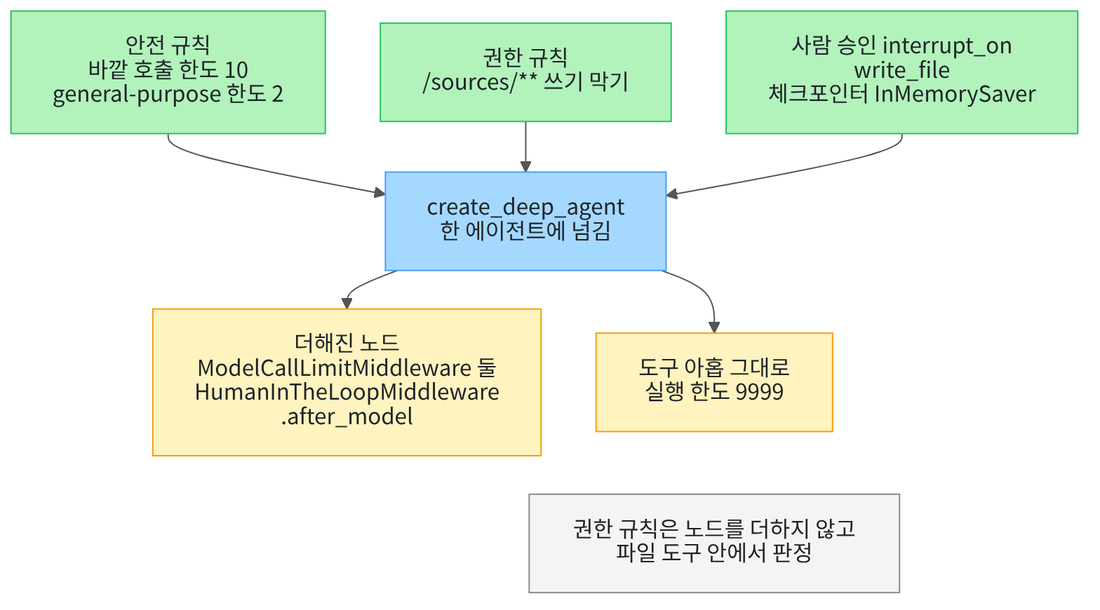

## 1. 준비

이 절은 이 챕터 본문의 마지막 절입니다.
01~07절에서 하나씩 본 기능 가운데 몇 가지를 한 에이전트에 함께 조립하고, 한 번 실행합니다.
여기에 모델이 고른 도구 요청을 실행 전에 막거나 멈추는 장치 둘을 더합니다.
하나는 파일 도구 안의 권한 규칙이고, 다른 하나는 사람 승인입니다.
마지막에는 운영에서 남는 한도와 기준을 한곳에 모읍니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langgraph: 1.2.11`이 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.
패키지 langgraph는 작은 그래프와 체크포인터, 이어 가기의 `Command`를 가져오려고 넣었습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
마지막 가져오기 줄은 앞에서 배운 함수 여섯을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·상태 형식(04절)·호출 한도(Ch 22)·모델·메시지·체크포인터(Ch 23)·그래프·Command(Ch 24) 이름을 가져옵니다
from deepagents import FilesystemMiddleware, FilesystemPermission, create_deep_agent
from deepagents.middleware.filesystem import FilesystemState
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command
# 앞 챕터와 01·07절에서 배운 함수 여섯은 도구 파일에서 가져옵니다(check_citations·call_args는 이 절에서 도구 파일에 더함)
from harness_tools import call_args, check_citations, estimate_cost, show_messages, sum_usage, tool_names

print("도구 파일에서 가져온 함수:", "call_args, check_citations, estimate_cost, show_messages, sum_usage, tool_names")

도구 파일에서 가져온 함수: call_args, check_citations, estimate_cost, show_messages, sum_usage, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: call_args, check_citations, estimate_cost, show_messages, sum_usage, tool_names`가 보입니다.
네 함수 `estimate_cost`·`show_messages`·`sum_usage`·`tool_names`의 뜻은 02절 1절에 적었습니다.
나머지 둘은 07절 노트북에서 처음 만든 함수이고, 이 절에서 07절 셀 글 그대로 도구 파일에 더했습니다.
함수 `check_citations`는 출처 표시가 가리키는 파일이 있는지 판정하고, `call_args`는 도구 요청의 인자 값을 모읍니다.

앞에서 배운 함수는 `harness_tools.py`에 모아 두었고, 파일을 열면 코드를 볼 수 있습니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
가져온 이름 가운데 `InMemorySaver`는 Ch 23 01절의 체크포인터입니다.
이름 `Command`는 Ch 24 01절에서 사람의 답으로 이어 갈 때 쓴 이름입니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 6절의 실행 셀과 이어 가기 셀에서만 나갑니다.

2~5절은 이 객체로 Deep Agent를 만들기만 하고, 모델을 부르지 않습니다.
이 절은 파일을 디스크에 쓰지 않고, 상태 칸 `files`만 씁니다.

## 2. 자료와 안전 규칙 준비하기

01절 안전 규칙대로, 모델을 부르는 에이전트에는 두 한도를 넣습니다.
다음 셀은 02절 셀과 같은 글의 general-purpose 명세입니다.

In [5]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도 둘을 넣습니다(01절 6절 모양)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
이 명세는 기본 general-purpose 서브에이전트의 자리를 바꾸고, 자기 호출 한도 2를 갖습니다.
모델이 `task`를 부르면, 한 번 부를 때마다 요청이 두 번까지만 나갑니다.

다음 셀은 03절 셀과 같은 글의 바깥 호출 한도입니다.

In [6]:
# 바깥 에이전트의 모델 요청을 열 번까지로 막는 호출 한도를 만듭니다(02절 셀과 한도만 다름)
outer_limit = ModelCallLimitMiddleware(run_limit=10, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 10


**결과 읽기** — 출력 줄 `바깥 호출 한도: 10`이 보입니다.
주석의 「02절 셀과 한도만 다름」은 이 셀을 처음 쓴 03절에서 적은 말입니다.
이 한도는 invoke 한 번 안의 모델 요청 수를 셉니다.
6절의 실행은 승인 자리에서 멈춘 뒤 이어 가므로, invoke 두 번으로 나뉩니다.
이 점이 한도에 주는 영향은 7절에서 봅니다.

다음 셀은 07절 셀과 같은 글의 교재용 자료 셋입니다.
실제 기관의 글이 아니라, 흐름을 보여 주려고 07절에서 정한 글입니다.

In [7]:
# 조사에 쓸 교재용 자료 셋을 파일 위치마다 정합니다(실제 기관의 글이 아님)
source_texts = {
    "/sources/closing-notice.md": "# 서가 정리 휴관 안내\n10월 셋째 주 토요일은 서가 정리로 자료실을 열지 않습니다.\n이날은 대출·연장·반납 창구를 열지 않습니다.",
    "/sources/return-box.md": "# 무인 반납함 안내\n자료실 정문 옆 무인 반납함은 휴관일에도 쓸 수 있습니다.\n반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.",
    "/sources/new-books.md": "# 새로 들어온 책\n이번 달에는 데이터 분석 입문서 세 권이 들어왔습니다.\n새 책은 들어온 날부터 일주일 동안 자료실 안에서만 볼 수 있습니다.",
}
print("자료 파일 위치:", list(source_texts))

자료 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md']


**결과 읽기** — 출력 줄 `자료 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md']`가 보입니다.
휴관 안내·무인 반납함 안내·새 책 소식 셋이고, 파일 위치는 모두 `/sources/`로 시작합니다.
이 절에서는 이 폴더를 자료 폴더라고 부르고, 3절에서 자료 폴더에 쓰기를 막습니다.

다음 셀은 04절 3절 셀과 같은 글의 작은 그래프 함수입니다.

In [8]:
# Deep Agent 하나를 받아, 그 도구 실행 노드 하나만 든 작은 그래프를 만들어 내놓습니다(상태 형식은 files 칸이 있는 FilesystemState)
def tools_only_graph(agent):
    builder = StateGraph(FilesystemState)
    builder.add_node("tools", agent.nodes["tools"].bound)
    builder.add_edge(START, "tools")
    builder.add_edge("tools", END)
    return builder.compile()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
작은 그래프에는 도구 실행 노드 하나뿐이라, 손 요청을 넣어도 모델을 부르지 않습니다.

다음 셀은 07절 3절처럼 손 요청 `write_file` 셋으로 자료를 상태 칸에 넣습니다.
이번에는 규칙을 하나도 넣지 않은 Deep Agent의 작은 그래프를 씁니다.
3절에서 만들 에이전트는 자료 폴더에 쓰기를 막아, 그 에이전트로는 자료를 넣을 수 없기 때문입니다.

In [9]:
# 모델 없이, 규칙이 없는 Deep Agent의 작은 그래프에 write_file 요청 셋을 손으로 넣어 자료를 상태 칸에 둡니다(07절 3절 모양)
seed_agent = create_deep_agent(model=model)
seed_graph = tools_only_graph(seed_agent)
write_calls = []
for path in source_texts:
    write_args = {"file_path": path, "content": source_texts[path]}
    write_calls.append({"name": "write_file", "args": write_args, "id": "hand_" + path, "type": "tool_call"})
write_request = AIMessage(content="", tool_calls=write_calls)
seed_result = seed_graph.invoke({"messages": [write_request]})
source_files = seed_result["files"]
print("상태 칸 files의 파일 위치:", list(source_files))

상태 칸 files의 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md']


**결과 읽기** — 라벨 `상태 칸 files의 파일 위치:` 뒤에 자료 셋의 위치가 보입니다.
이 셀까지 모델 요청은 0번입니다.
이 상태 칸을 `source_files`라는 이름으로 두고, 4~6절에서 입력에 넣습니다.

## 3. 한 에이전트에 조립하기

먼저 권한 규칙을 하나 만듭니다.
01절 4절에서는 파일 하나 `/blocked.txt`에 쓰기를 막는 규칙을 조립만 했습니다.
이번에는 자료 폴더 아래 모든 파일에 쓰기를 막습니다.
파일 위치 끝의 `**`는 그 폴더 아래의 모든 파일과 폴더를 뜻합니다.

In [10]:
# 자료 폴더 /sources/ 아래 모든 파일에 쓰기를 막는 권한 규칙 하나를 만듭니다(01절 4절 모양 — 파일 위치만 다름)
source_rule = FilesystemPermission(operations=["write"], paths=["/sources/**"], mode="deny")
print("막는 일:", source_rule.operations)
print("막는 파일 위치:", source_rule.paths)
print("규칙의 효과:", source_rule.mode)

막는 일: ['write']
막는 파일 위치: ['/sources/**']
규칙의 효과: deny


**결과 읽기** — 출력 줄 `막는 일: ['write']`, `막는 파일 위치: ['/sources/**']`, `규칙의 효과: deny`가 보입니다.
효과 `deny`는 맞는 요청을 막고, 오류 글을 담은 도구 메시지를 내는 규칙입니다.
효과에는 `allow`와 `interrupt`도 있고, `interrupt`는 막는 대신 사람 승인에 넘깁니다.
이 절은 막는 규칙과 사람 승인을 따로 줍니다.

다음 셀은 앞의 부품을 한 에이전트에 모두 넘깁니다.
인자 `interrupt_on=`에 적은 도구는 실행 전에 사람 승인을 받습니다.
멈춘 뒤 이어 가려면 멈춘 자리가 저장돼 있어야 해서, Ch 23 01절의 체크포인터도 넘깁니다.
시스템 메시지 글에는 찾고 읽은 뒤 보고 파일 `/reports/answer.md`에 적는 차례를 적었습니다.

In [11]:
# 호출 한도·명세·권한 규칙·사람 승인·체크포인터를 한 에이전트에 함께 넘깁니다(요청은 아직 보내지 않음)
report_text = "자료는 /sources/ 폴더의 파일에만 있습니다. 먼저 grep으로 관련 파일을 찾고, 찾은 파일을 read_file로 읽으세요. 그다음 파일에 적힌 내용만으로 두 문장의 한국어 답을 써서 write_file로 /reports/answer.md에 적으세요. 답의 문장마다 근거 파일 위치를 [/sources/파일 이름.md] 꼴로 붙이세요. 파일에 적은 뒤에는 적은 파일 위치를 한 문장으로 알려 주세요."
report_agent = create_deep_agent(
    model=model,
    system_prompt=report_text,
    middleware=[outer_limit],
    subagents=[helper_spec],
    permissions=[source_rule],
    interrupt_on={"write_file": True},
    checkpointer=InMemorySaver(),
)

**결과 읽기** — 에이전트를 만들기만 하는 셀이라 출력이 없습니다.
07절 조사 에이전트와 견주면 부품 셋이 더해졌습니다.
권한 규칙 `permissions=`, 사람 승인 `interrupt_on=`, 체크포인터 `checkpointer=`입니다.
할 일 목록과 우리 도구, 사용자 서브에이전트 명세는 넣지 않았습니다.
모두 요청 수를 늘리는 기능이라, 이 흐름에서는 뺐습니다.

다음 셀은 조립된 에이전트의 노드와 도구 수, 실행 한도를 봅니다.

In [12]:
# 조립된 에이전트의 노드 이름과 도구 수, 묶여 있는 실행 한도를 봅니다
report_graph = report_agent.get_graph()
print("노드:", list(report_graph.nodes))
report_tools = tool_names(report_agent)
print("도구 수:", len(report_tools))
print("실행 한도:", report_agent.config["recursion_limit"])

노드: ['__start__', 'model', 'tools', 'PatchToolCallsMiddleware.before_agent', 'ModelCallLimitMiddleware.before_model', 'ModelCallLimitMiddleware.after_model', 'HumanInTheLoopMiddleware.after_model', '__end__']
도구 수: 9
실행 한도: 9999


**결과 읽기** — 라벨 `노드:` 뒤에 노드 이름 여덟이 보입니다.
01절 4절에서 본 것처럼, 사람 승인은 노드 `HumanInTheLoopMiddleware.after_model` 하나로 붙었습니다.
호출 한도는 이름이 `ModelCallLimitMiddleware`로 시작하는 노드 둘로 붙었습니다.
권한 규칙이 더한 노드는 없습니다.
출력 줄 `도구 수: 9`와 `실행 한도: 9999`는 01절에서 본 기본값 그대로입니다.

## 4. 권한 규칙은 도구 안에서 판정합니다

권한 규칙은 노드를 더하지 않으니, 도구 실행 노드만 든 작은 그래프로도 확인할 수 있습니다.
다음 셀은 `write_file` 요청 둘을 손으로 만들어 한 응답에 담습니다.
하나는 보고 폴더 `/reports/`에, 다른 하나는 자료 폴더에 씁니다.
실행 전에 예상해 봅니다.
둘째 요청은 어떤 결과 상태로 끝날까요?

In [13]:
# 모델 없이, 보고 폴더와 자료 폴더에 쓰는 write_file 요청 둘을 손으로 만들어 조립한 에이전트의 작은 그래프에 넣습니다
allow_args = {"file_path": "/reports/check.md", "content": "점검 메모"}
deny_args = {"file_path": "/sources/new-books.md", "content": "바꾼 글"}
allow_call = {"name": "write_file", "args": allow_args, "id": "hand_allow_1", "type": "tool_call"}
deny_call = {"name": "write_file", "args": deny_args, "id": "hand_deny_1", "type": "tool_call"}
two_request = AIMessage(content="", tool_calls=[allow_call, deny_call])
guard_graph = tools_only_graph(report_agent)
guard_result = guard_graph.invoke({"messages": [two_request], "files": source_files})
show_messages(guard_result["messages"])

AIMessage | 도구 호출 요청: ['write_file', 'write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /reports/check.md
ToolMessage | 결과 상태: error | 내용: Error: permission denied for write on /sources/new-books.md


**결과 읽기** — `AIMessage` 줄 뒤에 `ToolMessage` 줄 둘이 보입니다.
첫째는 결과 상태 `success`, 내용 `Updated file /reports/check.md`입니다.
둘째는 결과 상태 `error`, 내용 `Error: permission denied for write on /sources/new-books.md`입니다.
결과 상태는 Ch 19 06절에서 본 도구 메시지의 칸 `status`입니다.
모델 없이 손으로 만든 요청이라, 이 결과는 몇 번 실행해도 같습니다.

설치판 `middleware/filesystem.py` 1727~1733행에서, 도구 `write_file`은 쓰기 전에 권한 규칙을 봅니다.
막히면 백엔드에 쓰지 않고, 오류 글을 담은 도구 메시지를 내놓습니다.
이 에이전트는 `write_file`에 사람 승인도 걸었지만, 이 작은 그래프에는 승인 노드가 없어 멈추지 않았습니다.

다음 셀은 실행 뒤 상태 칸을 봅니다.

In [14]:
# 실행 뒤 상태 칸 files의 파일 위치와, 새 책 소식 파일의 글이 2절에서 넣은 글 그대로인지 봅니다
print("상태 칸 files의 파일 위치:", list(guard_result["files"]))
guard_text = guard_result["files"]["/sources/new-books.md"]["content"]
print("새 책 소식이 그대로인가:", guard_text == source_texts["/sources/new-books.md"])

상태 칸 files의 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md', '/reports/check.md']
새 책 소식이 그대로인가: True


**결과 읽기** — 라벨 `상태 칸 files의 파일 위치:` 뒤에 자료 셋과 `/reports/check.md`가 보입니다.
출력 줄 `새 책 소식이 그대로인가: True`도 보입니다.
막힌 요청의 글은 상태 칸에 들어가지 않았고, 자료는 2절에서 넣은 글 그대로입니다.

05절에서는 같은 이름 미들웨어를 `middleware=`에 넣으면 기본 자리를 바꾼다고 보았습니다.
다음 셀은 같은 규칙에 같은 이름 `FilesystemMiddleware`를 넣은 에이전트에, 같은 손 요청 둘을 넣습니다.
실행 전에 예상해 봅니다.
둘째 요청은 이번에도 막힐까요?

In [15]:
# 값 바꿔 보기: 같은 규칙에 같은 이름 FilesystemMiddleware를 middleware=에 넣고, 같은 손 요청 둘을 넣어 봅니다
same_agent = create_deep_agent(model=model, permissions=[source_rule], middleware=[FilesystemMiddleware()])
same_graph = tools_only_graph(same_agent)
same_result = same_graph.invoke({"messages": [two_request], "files": source_files})
show_messages(same_result["messages"])
same_text = same_result["files"]["/sources/new-books.md"]["content"]
print("새 책 소식이 그대로인가:", same_text == source_texts["/sources/new-books.md"])

AIMessage | 도구 호출 요청: ['write_file', 'write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /reports/check.md
ToolMessage | 결과 상태: success | 내용: Updated file /sources/new-books.md
새 책 소식이 그대로인가: False


**결과 읽기** — 이번에는 `ToolMessage` 줄 둘 모두 결과 상태가 `success`입니다.
둘째 내용은 `Updated file /sources/new-books.md`이고, 출력 줄 `새 책 소식이 그대로인가: False`가 보입니다.
자료 폴더 쓰기가 막히지 않아, 새 책 소식의 글이 바뀌었습니다.

설치판 `graph.py` 201~235행에서, 같은 이름 미들웨어는 기본 미들웨어의 자리를 통째로 바꿉니다.
권한 규칙은 기본 `FilesystemMiddleware`에 넘겨지는데, 우리가 넣은 새 미들웨어에는 규칙이 없습니다.
그래서 규칙을 넘겼어도 쓰기 막기가 사라졌습니다.
권한 규칙과 파일 미들웨어 설정을 함께 쓸 때는, 이 셀처럼 손 요청으로 먼저 확인합니다.

## 5. 사람 승인으로 멈추고 이어 가기

사람 승인은 권한 규칙과 걸리는 자리가 다릅니다.
3절에서 본 승인 노드는 모델 응답을 받은 직후, 도구가 실행되기 전에 돕니다.
그래서 4절의 작은 그래프에서는 승인이 걸리지 않았습니다.
다음 셀은 승인 노드와 도구 실행 노드를 차례로 든 작은 그래프를 만드는 함수입니다.
Ch 24 01절처럼 멈춘 뒤 이어 가려면 체크포인터가 있어야 해서, 체크포인터도 인자로 받습니다.

In [16]:
# Deep Agent 하나와 체크포인터를 받아, 사람 승인 노드와 도구 실행 노드만 차례로 든 작은 그래프를 만들어 내놓습니다
def review_graph(agent, checkpointer):
    builder = StateGraph(FilesystemState)
    # 사람 승인 미들웨어의 노드 이름은 01절 4절에서 본 HumanInTheLoopMiddleware.after_model입니다
    builder.add_node("review", agent.nodes["HumanInTheLoopMiddleware.after_model"].bound)
    builder.add_node("tools", agent.nodes["tools"].bound)
    builder.add_edge(START, "review")
    builder.add_edge("review", "tools")
    builder.add_edge("tools", END)
    return builder.compile(checkpointer=checkpointer)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
노드 이름 `review`는 이 작은 그래프 안에서만 쓰는 이름입니다.
그 노드에는 조립한 에이전트의 승인 노드가 그대로 들어갑니다.

이 작은 그래프는 승인 노드 뒤에 도구 실행 노드로 곧장 갑니다.
노트북 밖에서 모델 없이 확인해 보니, 거절이나 대신 답하기 결정을 넣어도 쓰기가 그대로 실행되었습니다.
실제 에이전트는 짝 도구 메시지가 있는 요청을 건너뛰어, 거절한 쓰기를 실행하지 않습니다.
설치판 `agents/factory.py` 1953~1964행이 그 자리입니다.
그래서 이 그래프로는 승인만 봅니다.

다음 셀은 새 체크포인터로 이 작은 그래프를 만들고, 스레드 하나의 설정을 정합니다.

In [17]:
# 새 체크포인터로 승인 작은 그래프를 만들고, 스레드 하나의 설정을 정합니다(Ch 23 01절 thread_id)
hand_graph = review_graph(report_agent, InMemorySaver())
hand_nodes = hand_graph.get_graph().nodes
print("작은 그래프의 노드:", list(hand_nodes))
hand_config = {"configurable": {"thread_id": "hand-approval"}}

작은 그래프의 노드: ['__start__', 'review', 'tools', '__end__']


**결과 읽기** — 출력 줄 `작은 그래프의 노드: ['__start__', 'review', 'tools', '__end__']`가 보입니다.
승인 노드 뒤에 도구 실행 노드가 이어지고, 모델 노드는 없습니다.
그래서 이 그래프에 손 요청을 넣어도 모델 요청은 나가지 않습니다.

다음 셀은 보고 폴더에 쓰는 `write_file` 요청 하나를 손으로 만들어 넣습니다.
4절에서는 이 요청이 바로 실행되었습니다.

In [18]:
# 모델 없이, 보고 폴더에 쓰는 write_file 요청 하나를 손으로 만들어 넣고 멈췄는지 봅니다
report_call = {"name": "write_file", "args": allow_args, "id": "hand_report_1", "type": "tool_call"}
report_request = AIMessage(content="", tool_calls=[report_call])
hand_result = hand_graph.invoke({"messages": [report_request], "files": source_files}, hand_config)
print("결과 키:", list(hand_result))
hand_state = hand_graph.get_state(hand_config)
print("다음 노드:", hand_state.next)
print("멈춘 동안 보고 파일이 있는가:", "/reports/check.md" in hand_state.values["files"])

결과 키: ['messages', 'files', '__interrupt__']
다음 노드: ('review',)
멈춘 동안 보고 파일이 있는가: False


**결과 읽기** — 출력 줄 `결과 키: ['messages', 'files', '__interrupt__']`가 보입니다.
Ch 24 01절에서 본 것처럼, 결과 키 `__interrupt__`는 그래프가 멈춤 표시에서 멈췄다는 뜻입니다.
출력 줄 `다음 노드: ('review',)`는 승인 노드에서 멈춰 있다는 뜻입니다.
출력 줄 `멈춘 동안 보고 파일이 있는가: False`도 보입니다.
도구가 아직 실행되지 않아, 상태 칸에 보고 파일이 없습니다.

다음 셀은 멈춤 표시에 담긴 질문 값을 봅니다.

In [19]:
# 멈춤 표시의 질문 값에서, 멈춘 도구 요청과 고를 수 있는 결정을 봅니다
hand_value = hand_result["__interrupt__"][0].value
print("질문 값의 키:", list(hand_value))
for action in hand_value["action_requests"]:
    print("멈춘 도구 요청:", action["name"], "|", action["args"]["file_path"])
for review in hand_value["review_configs"]:
    print("고를 수 있는 결정:", review["allowed_decisions"])

질문 값의 키: ['action_requests', 'review_configs']
멈춘 도구 요청: write_file | /reports/check.md
고를 수 있는 결정: ['approve', 'edit', 'reject', 'respond']


**결과 읽기** — 출력 줄 `질문 값의 키: ['action_requests', 'review_configs']`가 보입니다.
Ch 24 01절에서는 우리 노드가 질문 값을 정했지만, 여기서는 사람 승인 미들웨어가 정한 모양입니다.
키 `action_requests`에는 멈춘 도구 요청이, `review_configs`에는 고를 수 있는 결정이 들어 있습니다.
출력 줄 `멈춘 도구 요청: write_file | /reports/check.md`가 보입니다.
출력 줄 `고를 수 있는 결정: ['approve', 'edit', 'reject', 'respond']`는 승인·고치기·거절·도구 대신 답하기입니다.

이어 가는 호출은 Ch 24 01절과 같은 `Command(resume=…)`입니다.
다른 점은 답의 모양입니다.
Ch 24에서는 `interrupt`가 내놓은 답을 우리 노드가 그대로 썼지만, 사람 승인 미들웨어는 답에서 키 `decisions`를 꺼냅니다.
그래서 답은 멈춘 도구 요청마다 결정 하나를 차례대로 담은 목록을, 키 `decisions`에 넣은 딕셔너리여야 합니다.
이 절은 이 목록을 결정 목록이라고 부릅니다.

회의에 올라온 안건마다 찬성이나 반대를 하나씩 적어 내는 표와 같습니다.
다음 셀은 멈춘 요청 하나에 승인 `{"type": "approve"}` 하나를 담은 결정 목록으로 이어 갑니다.

In [20]:
# 멈춘 도구 요청 하나에 승인 결정 하나를 담은 답으로, 같은 스레드를 이어 갑니다(Ch 24 01절 Command(resume=…))
hand_answer = {"decisions": [{"type": "approve"}]}
hand_after = hand_graph.invoke(Command(resume=hand_answer), hand_config)
show_messages(hand_after["messages"])
print("보고 파일이 있는가:", "/reports/check.md" in hand_after["files"])

AIMessage | 도구 호출 요청: ['write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /reports/check.md
보고 파일이 있는가: True


**결과 읽기** — `AIMessage` 줄 뒤에 결과 상태 `success`, 내용 `Updated file /reports/check.md`인 `ToolMessage` 줄이 보입니다.
출력 줄 `보고 파일이 있는가: True`도 보입니다.
승인 결정을 넣자 멈춰 있던 도구 요청이 실행되었습니다.
Ch 24 01절에서 본 것처럼, 이어 갈 때 멈춘 노드는 첫 줄부터 다시 실행됩니다.
설치판 `human_in_the_loop.py` 456행에서, 다시 실행된 승인 노드는 `interrupt`가 내놓은 우리 답에서 결정 목록을 꺼냅니다.

다음 셀은 Ch 24처럼 글 하나를 답으로 넘기면 어떻게 되는지, 새 스레드에서 봅니다.
실행 전에 예상해 봅니다.
글 `approve` 하나로도 이어 갈 수 있을까요?

In [21]:
# 값 바꿔 보기: 새 스레드에서 다시 멈춘 뒤, Ch 24 01절처럼 글 하나를 답으로 넘겨 봅니다(Ch 2 05절 try/except)
plain_config = {"configurable": {"thread_id": "hand-plain"}}
hand_graph.invoke({"messages": [report_request], "files": source_files}, plain_config)
try:
    hand_graph.invoke(Command(resume="approve"), plain_config)
except TypeError as error:
    print("받은 오류:", type(error).__name__, "|", error)

받은 오류: TypeError | string indices must be integers, not 'str'


**결과 읽기** — 출력 줄 `받은 오류: TypeError | string indices must be integers, not 'str'`가 보입니다.
글 `approve`가 그대로 `interrupt`의 답이 되고, 미들웨어가 그 글에서 키 `decisions`를 꺼내려다 오류가 났습니다.
같은 `Command(resume=…)`라도, 받는 쪽이 정한 모양으로 답을 넣어야 합니다.
이 셀은 오류를 받아 출력하고 끝까지 가지만, 실제 프로그램이었다면 여기서 멈춥니다.

## 6. 실제 모델로 한 흐름 실행하기

이제 조립한 에이전트에 2절의 자료와 질문 한 줄을 새 스레드로 넣어 실행합니다.
질문은 휴관일에 무인 반납함에 넣은 책이 언제 반납 처리되는지 묻습니다.
모델이 보고 파일에 쓰려고 `write_file`을 요청하면, 승인 노드에서 멈출 것입니다.
실행 전에 예상해 봅니다.
멈출 때까지 모델은 어떤 도구를 차례로 요청할까요?

In [22]:
# 2절 자료와 질문 한 줄을 새 스레드로 넣어 실행합니다(모델이 write_file을 요청하면 승인 자리에서 멈춤)
question = "휴관일에 무인 반납함에 넣은 책은 언제 반납 처리되나요?"
run_config = {"configurable": {"thread_id": "report-run"}}
first_input = {"messages": [HumanMessage(content=question)], "files": source_files}
input_count = len(first_input["messages"])
first_result = report_agent.invoke(first_input, run_config)
print("멈췄는가:", "__interrupt__" in first_result)
print("멈출 때까지의 결과 메시지 수:", len(first_result["messages"]))

멈췄는가: True
멈출 때까지의 결과 메시지 수: 6


**결과 읽기** — 라벨 `멈췄는가:` 뒤의 값으로, 첫 실행이 승인 자리에서 멈췄는지 봅니다.
라벨 `멈출 때까지의 결과 메시지 수:` 뒤에는 멈출 때까지 쌓인 메시지 수가 보입니다.

이번 실행에서는 `멈췄는가: True`, `멈출 때까지의 결과 메시지 수: 6`이었습니다.
질문 하나 뒤에 `grep`·`read_file`·`write_file`을 하나씩 요청한 응답과, 앞의 두 도구 메시지가 쌓였습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 모두 이 차례로 멈췄습니다.

다음 셀은 멈춘 도구 요청을 보고, 요청마다 승인 결정 하나를 만듭니다.

In [23]:
# 멈춘 도구 요청마다 승인 결정 하나를 목록에 붙입니다(사람의 답 자리에 코드가 넣는 값)
decisions = []
if "__interrupt__" in first_result:
    paused_value = first_result["__interrupt__"][0].value
    for action in paused_value["action_requests"]:
        print("멈춘 도구 요청:", action["name"], "|", action["args"]["file_path"])
        decisions.append({"type": "approve"})
print("넣을 결정 수:", len(decisions))

멈춘 도구 요청: write_file | /reports/answer.md
넣을 결정 수: 1


**결과 읽기** — 라벨 `멈춘 도구 요청:` 뒤에 도구 이름과 파일 위치가 보입니다.
라벨 `넣을 결정 수:` 뒤에는 결정 목록의 길이가 보이고, 멈춘 도구 요청 수와 같게 만들었습니다.
이 노트북에서 사람의 답은 사람이 고른 값이 아니라, 셀이 모든 요청에 넣는 승인입니다.
Ch 24에서도 사람의 답은 셀에 적은 값이었습니다.
실제로는 이 자리에서 사람이 질문 값을 보고 결정을 고릅니다.

이번 실행에서는 `멈춘 도구 요청: write_file | /reports/answer.md`, `넣을 결정 수: 1`이었습니다.
모델은 시스템 메시지 글이 정한 보고 파일 위치에 쓰려 했고, 그 요청 하나가 승인 자리에서 멈췄습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.

다음 셀은 결정 목록으로 같은 스레드를 이어 갑니다.

In [24]:
# 결정이 있으면 결정 목록으로 같은 스레드를 이어 가고, 없으면 첫 결과를 그대로 씁니다
run_result = first_result
if len(decisions) > 0:
    run_result = report_agent.invoke(Command(resume={"decisions": decisions}), run_config)
run_messages = run_result["messages"]
print("다시 멈췄는가:", "__interrupt__" in run_result)
print("결과 메시지 수:", len(run_messages))

다시 멈췄는가: False
결과 메시지 수: 8


**결과 읽기** — 라벨 `다시 멈췄는가:`와 `결과 메시지 수:` 뒤에 값이 하나씩 보입니다.
이어 간 뒤의 결과 메시지는 멈추기 전 메시지에 이어 붙은, 스레드 전체의 목록입니다.

이번 실행에서는 `다시 멈췄는가: False`, `결과 메시지 수: 8`이었습니다.
멈추기 전 여섯에, 보고 파일을 적은 도구 메시지와 마지막 답이 더해졌습니다.
새 커널 두 번째도 8이었지만, 노트북 밖 다섯 번 가운데 네 번은 10이었습니다.
그 네 번은 이어 간 뒤 방금 적은 보고 파일을 `read_file`로 다시 읽고 나서 답했습니다.
시스템 메시지 글이 시키지 않은 일이라, 이어 간 뒤의 차례는 실행마다 달라질 수 있습니다.

다음 셀은 Ch 19 06절 함수 `show_messages`로 결과 메시지를 차례로 봅니다.

In [25]:
# 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("결과 메시지:")
show_messages(run_messages)

결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['grep']
ToolMessage | 결과 상태: success | 내용: /sources/return-box.md
AIMessage | 도구 호출 요청: ['read_file']
ToolMessage | 결과 상태: success | 내용: 1  # 무인 반납함 안내
2  자료실 정문 옆 무인 반납함은 휴관일에도 쓸 수 있습니다.
3  반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.
AIMessage | 도구 호출 요청: ['write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /reports/answer.md
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래가 결과 메시지의 차례입니다.
`AIMessage` 줄에는 모델이 요청한 도구 이름이, `ToolMessage` 줄에는 결과 상태와 도구가 낸 글이 보입니다.
마지막 `AIMessage` 줄은 도구 요청이 없는 응답이고, 모델이 쓴 답입니다.

이번 실행에서 모델은 `grep`·`read_file`·`write_file`을 한 응답에 하나씩 요청했고, 이어 간 뒤 바로 답했습니다.
멈출 때까지의 차례는 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.
이번 `grep` 도구 메시지는 무인 반납함 안내 하나를 찾았고, 모델은 그 파일을 읽었습니다.
모델이 `grep`에 넣은 낱말은 노트북 밖 다섯 번에서 두 가지로 갈렸습니다.

다음 셀은 실행 뒤 상태 칸 `files`를 봅니다.

In [26]:
# 실행 뒤 상태 칸 files의 파일 위치와, 자료 셋의 글이 2절에서 넣은 글 그대로인지 봅니다
print("상태 칸 files의 파일 위치:", list(run_result["files"]))
sources_same = True
for path in source_texts:
    if run_result["files"][path]["content"] != source_texts[path]:
        sources_same = False
print("자료 셋이 그대로인가:", sources_same)

상태 칸 files의 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md', '/reports/answer.md']
자료 셋이 그대로인가: True


**결과 읽기** — 라벨 `상태 칸 files의 파일 위치:` 뒤에 파일 위치 목록이 보입니다.
라벨 `자료 셋이 그대로인가:` 뒤의 값으로, 2절에서 넣은 자료의 글이 바뀌지 않았는지 봅니다.

이번 실행에서는 상태 칸에 `/reports/answer.md`가 더해졌고, `자료 셋이 그대로인가: True`였습니다.
승인한 `write_file`은 보고 폴더에 썼고, 모델은 자료 폴더에 쓰려 하지 않았습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.
그래서 이 실행에는 권한 규칙이 막을 요청이 없었고, 권한 판정은 4절의 손 요청으로만 보았습니다.

다음 셀은 보고 파일의 글을 보고, 07절 함수 `check_citations`로 출처 표시를 판정합니다.

In [27]:
# 보고 파일이 있으면 그 글을 보고, 출처 표시를 2절 자료가 든 상태 칸으로 판정합니다(07절 함수 check_citations)
report_path = "/reports/answer.md"
if report_path in run_result["files"]:
    report_body = run_result["files"][report_path]["content"]
    print("보고 파일의 글:")
    print(report_body)
    print("출처 판정:", check_citations(report_body, source_files))

보고 파일의 글:
휴관일에 무인 반납함에 넣은 책은 다음 운영일에 반납 처리됩니다. [/sources/return-box.md]
이 내용은 무인 반납함 안내에 적혀 있습니다. [/sources/return-box.md]
출처 판정: [{'인용': '/sources/return-box.md', '있는가': True}, {'인용': '/sources/return-box.md', '있는가': True}]


**결과 읽기** — 라벨 `보고 파일의 글:` 아래가 모델이 보고 파일에 적은 글입니다.
라벨 `출처 판정:` 뒤에는 출처 표시마다 판정 한 줄이 목록으로 보입니다.
보고 파일이 없으면 이 셀은 아무것도 출력하지 않습니다.

이번 실행의 보고 파일은 두 문장이고, 두 문장 모두 무인 반납함 안내의 파일 위치를 붙였습니다.
출처 판정은 두 줄 모두 `True`였습니다.
새 커널 두 번째는 둘째 문장의 글이 달랐고, 판정은 같았습니다.
07절에서 본 것처럼, `True`는 인용한 파일이 상태 칸에 있다는 뜻일 뿐입니다.
보고 파일의 글과 판정은 모델 글에서 나온 값이라 결론에 쓰지 않습니다.

## 7. 요청 수와 운영 한계

이 흐름은 멈췄다가 이어 가서 invoke 두 번으로 나뉘었습니다.
그래도 결과 메시지에는 같은 스레드의 메시지가 모두 쌓여 있습니다.
서브에이전트를 부르지 않았다면, 넣은 질문 뒤의 응답 수가 이 흐름의 요청 수 전부입니다.

다음 셀은 도구를 요청한 응답 수와 `task` 요청 수를 셉니다.
07절 6절 셀에 넣은 질문 뒤만 자르는 줄 하나를 더하고, 첫 줄 주석을 바꾼 글입니다.
더한 줄은 넣은 질문 뒤의 메시지만 잘라 `run_new`에 담는 줄입니다.

In [28]:
# 넣은 질문 뒤의 메시지만 잘라, 도구를 요청한 응답 수와 task 요청 수를 셉니다(07절 6절 셀에 첫 줄 run_new만 더함)
run_new = run_messages[input_count:]
tool_replies = 0
for message in run_new:
    if type(message).__name__ == "AIMessage":
        if len(message.tool_calls) > 0:
            tool_replies = tool_replies + 1
task_types = call_args(run_new, "task", "subagent_type")
print("도구를 요청한 응답 수:", tool_replies)
print("task 요청 수:", len(task_types))

도구를 요청한 응답 수: 3
task 요청 수: 0


**결과 읽기** — 라벨 `도구를 요청한 응답 수:`와 `task 요청 수:` 뒤에 수가 하나씩 보입니다.
도구 `task` 요청이 0이면 서브에이전트 요청이 없으니, 결과 메시지만 세면 됩니다.

이번 실행에서는 `도구를 요청한 응답 수: 3`, `task 요청 수: 0`이었습니다.
새 커널 두 번째도 같았고, `task` 요청은 노트북 밖 다섯 번에서도 모두 0이었습니다.
다만 노트북 밖 다섯 번 가운데 네 번은 이어 간 뒤 보고 파일을 다시 읽어, 도구를 요청한 응답이 4였습니다.

다음 셀은 07절 셀과 같은 글로 요청 수와 토큰을 세고, 도구를 요청한 응답 수 + 1과 견줍니다.

In [29]:
# 이번 실행이 더한 메시지만 Ch 19 05절 함수 sum_usage로 세고, 도구를 요청한 응답 수 + 1과 견줍니다
run_usage = sum_usage(run_new)
print("요청 수:", run_usage["requests"])
print("도구를 요청한 응답 수 + 1과 같은가:", run_usage["requests"] == tool_replies + 1)
print("입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])

요청 수: 4
도구를 요청한 응답 수 + 1과 같은가: True
입력 토큰: 8104 | 출력 토큰: 160


**결과 읽기** — 출력 줄 `도구를 요청한 응답 수 + 1과 같은가: True`가 보입니다.
모델은 도구 결과를 받을 때마다 다시 요청을 받고, 도구 요청이 없는 응답에서 멈춥니다.
승인 자리에서 멈춘 동안에는 요청이 나가지 않아, 이어 간 흐름에도 이 셈이 그대로 맞습니다.

이번 실행에서는 `요청 수: 4`, `입력 토큰: 8104 | 출력 토큰: 160`이었습니다.
6절 결과 메시지로 보면 멈출 때까지 3번, 이어 간 뒤 1번입니다.
새 커널 두 번째도 요청은 4번이었고, 입력 8110·출력 164로 토큰은 조금 달랐습니다.
노트북 밖 다섯 번 가운데 네 번처럼 이어 간 뒤 보고 파일을 다시 읽으면, 요청은 5번이 됩니다.

다음 셀은 02절 셀과 같은 글로 예상 비용을 셉니다.

In [30]:
# 2026-09-17 요금표(100만 토큰당 달러)로 이번 실행의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
run_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(run_cost, 6)
print("예상 비용(달러):", rounded_cost)

예상 비용(달러): 0.006798


**결과 읽기** — 라벨 `예상 비용(달러):` 뒤에 어림값이 보입니다.
입력 토큰을 모두 입력 요금으로 센 어림이고, 청구 금액이 아닙니다.

이번 실행에서는 `예상 비용(달러): 0.006798`이었습니다.
새 커널 두 번째는 0.006821달러였고, 노트북 밖 다섯 번은 0.006776에서 0.008615달러 사이였습니다.

마지막 셀은 이 절의 에이전트에 걸린 한도와 기준을 한곳에 모읍니다.
반복 수 하나로 뭉뚱그려 부르지 않고, 무엇을 세는 한도인지 라벨에 함께 적었습니다.

In [31]:
# 이 절의 에이전트에 걸린 한도와 기준을 무엇을 세는지와 함께 모아 봅니다(요약 기준은 05절 셀과 같은 셈)
max_input_tokens = model.profile["max_input_tokens"]
summary_fraction = 0.85
summary_threshold = int(max_input_tokens * summary_fraction)
print("실행 한도(그래프 단계 수):", report_agent.config["recursion_limit"])
print("바깥 호출 한도(invoke 한 번의 요청 수):", outer_limit.run_limit)
print("general-purpose 호출 한도(task 한 번의 요청 수):", helper_limit.run_limit)
print("요약이 켜지는 기준(토큰):", summary_threshold)

실행 한도(그래프 단계 수): 9999
바깥 호출 한도(invoke 한 번의 요청 수): 10
general-purpose 호출 한도(task 한 번의 요청 수): 2
요약이 켜지는 기준(토큰): 340000


**결과 읽기** — 출력 줄 `실행 한도(그래프 단계 수): 9999`가 보입니다.
Ch 20 03절의 실행 한도이고, 01절에서 본 Deep Agent의 기본값입니다.
출력 줄 `바깥 호출 한도(invoke 한 번의 요청 수): 10`과 `general-purpose 호출 한도(task 한 번의 요청 수): 2`도 보입니다.
둘은 Ch 16 04절·Ch 22 04절의 호출 한도이고, Ch 17 03절의 바퀴 한도와는 다른 한도입니다.
출력 줄 `요약이 켜지는 기준(토큰): 340000`은 05절에서 본 셈 그대로입니다.

넷이 세는 것은 서로 다릅니다.
실행 한도는 그래프가 거친 단계 수를, 호출 한도는 invoke 한 번 안의 모델 요청 수를 셉니다.
요약 기준은 한도가 아니라, 모델이 받은 글의 토큰이 이만큼이면 요약을 시작하는 기준입니다.
이 노트북의 실행은 이 기준에 한참 못 미쳐, 요약이 일어나지 않았습니다.
한도가 닿지 않는 자리는 교재 본문의 운영 한계 표에 모았습니다.

## 정리

1. 권한 규칙은 파일 도구 안에서 판정해, 자료 폴더 쓰기를 결과 상태 `error`로 막습니다. 같은 이름 `FilesystemMiddleware`를 넣으면 이 규칙이 사라집니다.
2. 사람 승인은 모델 응답 뒤 승인 노드에서 멈추고, 결정 목록 `{"decisions": [...]}`을 담은 `Command(resume=…)`로 이어 갑니다.
3. 요청 수는 도구를 요청한 응답 수 + 1입니다. 한도마다 세는 것이 달라, 한 응답의 `task` 요청 수처럼 어느 한도도 세지 않는 자리가 남습니다.

이 절로 Ch 27 본문이 끝납니다.
09절은 이 챕터의 실습입니다.
파일 도구와 사람 승인을 메모 에이전트 하나에 모으고, 승인을 켠 실행과 끈 실행을 견줍니다.